# Real Estate Fund Model: NAV, Bank Covenants and Liquidation Strategy

A diversified real estate fund (offices, retail, logistics, residential, hotels) has just
been through a market correction: values are down, a large office tower is 40% empty, and
the loan-to-value ratio has crept above the bank's limit. The fund manager has to answer
three questions:

1. **Where is the fund going?** A 10-year cash-flow and NAV projection.
2. **How close are we to breaking the bank covenants**, and under which scenarios?
3. **If the fund is wound down, in what order and how fast should we sell** to return the
   most value to investors?

All buildings and figures are fictitious.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("refund.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/20-real-estate-fund-model")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from refund import sample_fund, project, liquidation, FIRE_SALE_DISCOUNT

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL, GOLD = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f", "#b08d3c"
fund = sample_fund()
book = pd.DataFrame([{"Asset": a.name, "Sector": a.sector, "Value (EUR m)": a.value, "Occupancy": a.occupancy,
                      "Yield": a.cap_rate, "NOI (EUR m)": a.noi} for a in fund.assets]).set_index("Asset")
print(f"Portfolio {fund.portfolio_value():.0f}m | debt {fund.debt:.0f}m | NAV {fund.nav():.0f}m = {fund.nav_per_share():,.0f} EUR per share")
print(f"LTV {fund.ltv():.1%} (covenant max {fund.max_ltv:.0%})  |  ICR {fund.icr():.2f}x (covenant min {fund.min_icr:.1f}x)")
book.style.format({"Value (EUR m)": "{:.1f}", "Occupancy": "{:.0%}", "Yield": "{:.2%}", "NOI (EUR m)": "{:.2f}"})

Portfolio 395m | debt 160m | NAV 247m = 1,122 EUR per share
LTV 40.5% (covenant max 40%)  |  ICR 3.28x (covenant min 2.0x)


,Sector,Value (EUR m),Occupancy,Yield,NOI (EUR m)
Asset,,,,,
Paris La Défense tower,Office,41.8,62%,6.00%,2.51
Lyon Part-Dieu offices,Office,32.2,78%,5.80%,1.87
Lille business park,Office,16.6,70%,7.00%,1.16
Marseille Euromed offices,Office,27.7,85%,6.20%,1.72
Retail park Bordeaux,Retail,25.0,88%,6.80%,1.70
High-street Nice,Retail,17.5,95%,5.00%,0.87
Shopping centre Rennes,Retail,31.7,80%,7.20%,2.28
Logistics hub Lyon,Logistics,43.3,98%,5.00%,2.16
Last-mile Paris Nord,Logistics,29.4,100%,4.70%,1.38


Each building is valued by capitalising its net operating income:
$\text{Value} = \text{NOI} / \text{yield}$, with $\text{NOI} = \text{rent} \times \text{occupancy} \times (1 - 8\%)$.
The fund starts **in breach of its LTV covenant** (40.5% for a 40% maximum). In practice the
bank would grant a waiver for a few quarters, provided the manager presents a credible plan.

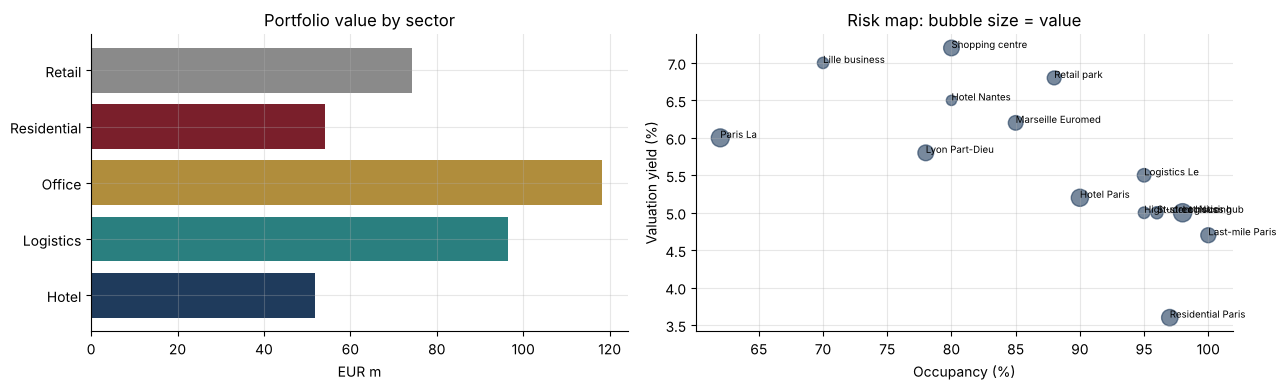

In [2]:
by_sector = book.groupby("Sector").agg(value=("Value (EUR m)", "sum"), noi=("NOI (EUR m)", "sum"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].barh(by_sector.index, by_sector["value"], color=[NAVY, TEAL, GOLD, BORDEAUX, GREY])
axes[0].set(xlabel="EUR m", title="Portfolio value by sector")
axes[1].scatter(book["Occupancy"] * 100, book["Yield"] * 100, s=book["Value (EUR m)"] * 4, color=NAVY, alpha=0.6)
for name, row in book.iterrows():
    axes[1].annotate(name.split()[0] + " " + name.split()[1], (row["Occupancy"] * 100, row["Yield"] * 100), fontsize=7)
axes[1].set(xlabel="Occupancy (%)", ylabel="Valuation yield (%)", title="Risk map: bubble size = value")
plt.tight_layout(); plt.savefig("images/portfolio.png", dpi=150); plt.show()

## 1. Ten-year projection and scenarios

Rents are indexed at 2% a year; 85% of the cash flow (after interest, capex and fees) is
distributed and the rest is retained. Three scenarios:

- **Base:** yields and occupancy stay where they are.
- **Yield shock:** valuation yields rise by 75 bp in year 1 (rates up, buyers scarce).
- **Occupier crisis:** occupancy falls by 10 points in years 1 and 2.

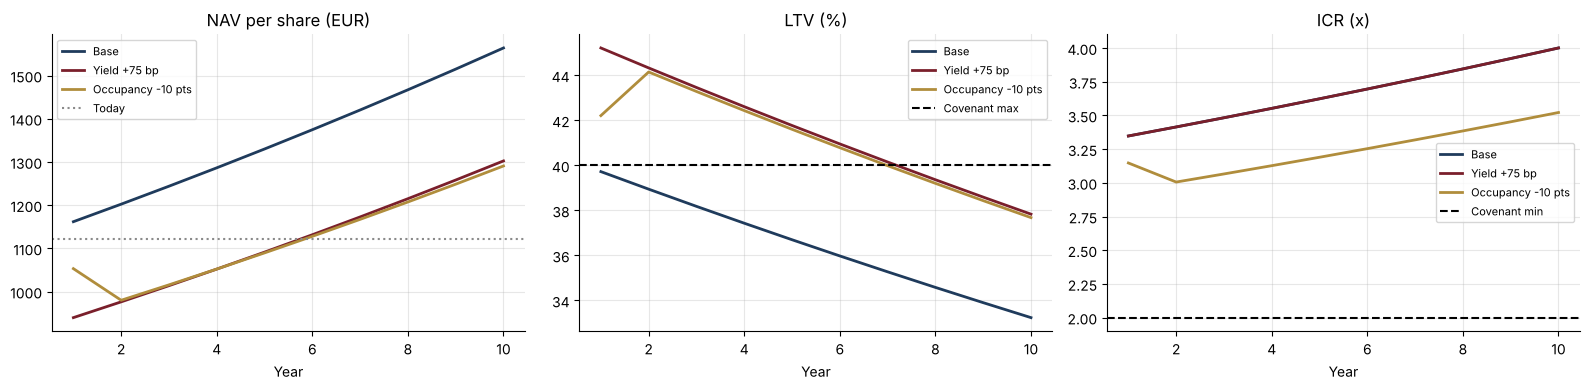

,NAV/share year 1,NAV/share year 10,Peak LTV,Years in LTV breach,Min ICR,Total distributions (EUR m)
Base,1161.839,1563.874,0.397,0.0,3.348,60.540
Yield +75 bp,939.843,1302.474,0.452,7.0,3.348,66.004
Occupancy -10 pts,1053.201,1290.811,0.441,6.0,3.006,41.679


In [3]:
scenarios = {"Base": project(fund), "Yield +75 bp": project(fund, cap_shift={1: 0.0075}),
             "Occupancy -10 pts": project(fund, occupancy_change={1: -0.05, 2: -0.05})}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (name, p), c in zip(scenarios.items(), [NAVY, BORDEAUX, GOLD]):
    axes[0].plot(p.index, p["NAV per share"], color=c, lw=2, label=name)
    axes[1].plot(p.index, p["LTV"] * 100, color=c, lw=2, label=name)
    axes[2].plot(p.index, p["ICR"], color=c, lw=2, label=name)
axes[0].axhline(fund.nav_per_share(), color=GREY, ls=":", label="Today")
axes[1].axhline(fund.max_ltv * 100, color="black", ls="--", label="Covenant max")
axes[2].axhline(fund.min_icr, color="black", ls="--", label="Covenant min")
for ax, t in zip(axes, ["NAV per share (EUR)", "LTV (%)", "ICR (x)"]):
    ax.set(title=t, xlabel="Year"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/projection.png", dpi=150); plt.show()
pd.DataFrame({name: {"NAV/share year 1": p["NAV per share"].iloc[0], "NAV/share year 10": p["NAV per share"].iloc[-1],
                     "Peak LTV": p["LTV"].max(), "Years in LTV breach": int(p["LTV breach"].sum()),
                     "Min ICR": p["ICR"].min(), "Total distributions (EUR m)": p["distribution"].sum()}
              for name, p in scenarios.items()}).T.round(3)

**Reading the scenarios.** In the base case, indexation slowly lifts values and the LTV drops
back under 40% within a year. The ICR is never the problem (above 3x): the covenant at risk
is the **LTV**, because it depends on valuations, which move much more than rents. A 75 bp
rise in yields wipes out about a fifth of the NAV and keeps the fund in breach for years.

## 2. How much shock can the fund absorb?

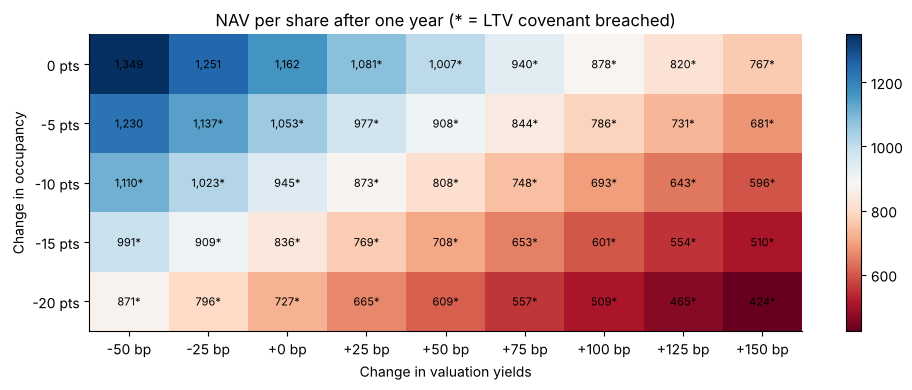

In [4]:
shifts = np.arange(-0.005, 0.0151, 0.0025)
occs = np.arange(0.0, -0.21, -0.05)
nav_grid = pd.DataFrame([[project(fund, years=1, cap_shift={1: s}, occupancy_change={1: o})["NAV per share"].iloc[0] for s in shifts]
                         for o in occs], index=[f"{o * 100:.0f} pts" for o in occs], columns=[f"{s * 1e4:+.0f} bp" for s in shifts])
ltv_grid = pd.DataFrame([[project(fund, years=1, cap_shift={1: s}, occupancy_change={1: o})["LTV"].iloc[0] for s in shifts]
                         for o in occs], index=nav_grid.index, columns=nav_grid.columns)
fig, ax = plt.subplots(figsize=(10, 4))
im = ax.imshow(nav_grid.values, cmap="RdBu", aspect="auto")
ax.set_xticks(range(len(shifts)), nav_grid.columns); ax.set_yticks(range(len(occs)), nav_grid.index)
for i in range(len(occs)):
    for j in range(len(shifts)):
        flag = "*" if ltv_grid.values[i, j] > fund.max_ltv else ""
        ax.text(j, i, f"{nav_grid.values[i, j]:,.0f}{flag}", ha="center", va="center", fontsize=8)
ax.set(xlabel="Change in valuation yields", ylabel="Change in occupancy", title="NAV per share after one year (* = LTV covenant breached)")
ax.grid(False); plt.colorbar(im); plt.tight_layout(); plt.savefig("images/sensitivity.png", dpi=150); plt.show()

## 3. Winding the fund down: in which order, and how fast?

Investors want their money back and the fund is to be liquidated. Five strategies:

| Strategy | Description |
|---|---|
| Fire sale | everything sold now, at forced-sale discounts (8% logistics to 25% retail) |
| Liquid first, 3 years | logistics and residential first, offices and retail last |
| Hardest first, 3 years | offices and retail first, while the market can still absorb them |
| Cure then hold | sell logistics now to fix the LTV, sell the rest in years 3 to 5 |
| Slow, 5 years | spread evenly over five years |

Sales repay the bank first (it is senior); rents from buildings still held are distributed.
Each strategy is tested in two markets: a **recovery** (yields fall 50 bp over years 2-3) and a
**second downturn** (yields rise 75 bp in year 2). Investor cash is discounted at 7%.

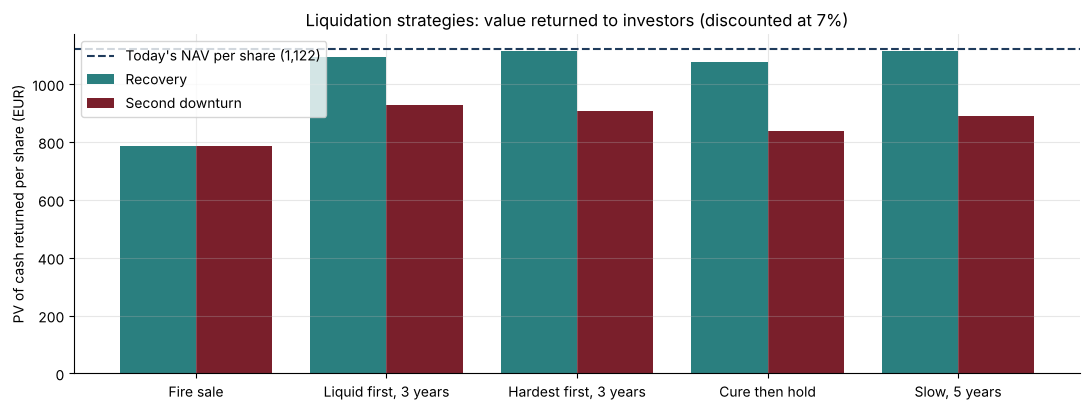

,"PV per share, recovery","Years in LTV breach, recovery","PV per share, second downturn","Years in LTV breach, second downturn",Worst case
Strategy,,,,,
Fire sale,788.0,0,788.0,0,788.0
"Liquid first, 3 years",1095.0,1,928.0,1,928.0
"Hardest first, 3 years",1116.0,1,908.0,1,908.0
Cure then hold,1076.0,0,839.0,0,839.0
"Slow, 5 years",1116.0,1,891.0,1,891.0


In [5]:
names = [a.name for a in fund.assets]
sector = {a.name: a.sector for a in fund.assets}
liquid_order = sorted(names, key=lambda n: ["Logistics", "Residential", "Hotel", "Retail", "Office"].index(sector[n]))
hard_order = list(reversed(liquid_order))
logistics = [n for n in names if sector[n] == "Logistics"]
rest = [n for n in names if sector[n] != "Logistics"]
strategies = {
    "Fire sale": (names, [0] * 14),
    "Liquid first, 3 years": (liquid_order, list(np.repeat([1, 2, 3], [5, 5, 4]))),
    "Hardest first, 3 years": (hard_order, list(np.repeat([1, 2, 3], [5, 5, 4]))),
    "Cure then hold": (logistics + rest, [0] * len(logistics) + list(np.repeat([3, 4, 5], [4, 4, 3]))),
    "Slow, 5 years": (names, [1 + i % 5 for i in range(14)]),
}
markets = {"Recovery": {2: -0.0025, 3: -0.0025}, "Second downturn": {2: 0.0075}}
rows, logs = [], {}
for sname, (order, sched) in strategies.items():
    row = {"Strategy": sname}
    for mname, path in markets.items():
        res = liquidation(fund, order, sched, market_path=path)
        row[f"PV per share, {mname.lower()}"] = res["PV per share"]
        row[f"Years in LTV breach, {mname.lower()}"] = int(res["log"]["LTV breach"].sum())
        logs[(sname, mname)] = res
    rows.append(row)
wind = pd.DataFrame(rows).set_index("Strategy")
wind["Worst case"] = wind[[c for c in wind.columns if c.startswith("PV")]].min(axis=1)
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(wind))
ax.bar(x - 0.2, wind["PV per share, recovery"], width=0.4, color=TEAL, label="Recovery")
ax.bar(x + 0.2, wind["PV per share, second downturn"], width=0.4, color=BORDEAUX, label="Second downturn")
ax.axhline(fund.nav_per_share(), color=NAVY, ls="--", label=f"Today's NAV per share ({fund.nav_per_share():,.0f})")
ax.set_xticks(x, wind.index); ax.set_ylabel("PV of cash returned per share (EUR)"); ax.legend()
ax.set_title("Liquidation strategies: value returned to investors (discounted at 7%)")
plt.tight_layout(); plt.savefig("images/liquidation.png", dpi=150); plt.show()
wind.round(0)

In [6]:
best = wind["Worst case"].idxmax()
print(f"Most robust strategy (best worst case): {best}")
logs[(best, "Second downturn")]["log"].round(2)

Most robust strategy (best worst case): Liquid first, 3 years


,sold (EUR m),debt,remaining value,LTV,LTV breach,paid to investors
year,,,,,,
0,0.00,160.00,394.89,0.41,True,10.00
1,149.81,10.19,247.94,0.04,False,5.43
2,113.08,0.00,108.56,0.00,False,110.36
3,107.99,0.00,0.00,0.00,False,113.55


**Reading the result.** The fire sale is the worst choice in both markets: forced-sale
discounts on offices and retail destroy far more value than they save in time. Among the
orderly strategies, the decision is a trade-off between **market risk** (waiting exposes the
fund to a second downturn) and **liquidity discount**; the robust choice is the one with the
best worst case, not the best base case. Every orderly strategy also cures the LTV breach
quickly, because sale proceeds repay the bank first.

## Conclusions
- Valuation yields, not rents, drive the covenant risk: the LTV is the binding covenant.
- A one-year sensitivity grid shows which combinations of yield and vacancy shocks break it.
- In a wind-down, order and timing matter: comparing strategies across several market paths
  and choosing the best worst case is more defensible than optimising one forecast.
- **Next steps:** lease-by-lease cash flows (break options, indexation caps), refinancing
  risk at debt maturity, redemption queues, and a Monte Carlo of yields instead of two paths.